# Homework 03 (Data Streaming): Coding

Nome Cognome: Luca Simonelli

### Algoritmo 1
>INPUT: a stream $S$, two parameters $\delta>0, \epsilon > 0$;  
>IN MEMORY: an integer matrix $H$ of counters $H_{k,j}, k \in\{0, \ldots , K-1\} , j \in \{0, \ldots , J-1\}$;  
>QUERYING OUTPUT: for any $1 \leq i \leq n$, estimation of ${F}[i]$ with $\hat{F}[i]$ given below;  
>
>// Initialization of hash functions and memory space  
>$K \longleftarrow \lceil \log \tfrac{1}{\delta} \rceil$;   
>$J \longleftarrow \lceil \tfrac{e}{\epsilon} \rceil$;
>
>// definition of the K hash functions  
>FOR $k = 0, \ldots , K$:  
>&ensp;$h_k :\mathbb{Z}_+ \to \{0, \ldots , J-1\}$;  
>ENDFOR
>
>// initialization of memory space: set to $0$ the matrix of counters  
>$H_{k,j} =0$, $k = 0, \ldots , K-1$, $j = 0, \ldots , J-1$  
>
>// Streaming Algorithm  
>WHILE $\ldots,a_l,\ldots$ in stream $S$:  
>&ensp;FOR $k \in \{0,\ldots, K-1\}$:  
>&ensp;&ensp;$H_{k,h_k(a_l)} \longleftarrow H_{k,h_k(a_l)} + 1$;  
>&ensp;ENDFOR  
>ENDWHILE  
>
>// Querying Algorithm  
>INPUT: an integer $i$;  
>RETURN $\hat{F}[i] = \min_{k=0,\ldots,K-1} H_{k,h_k(i)}.$  
>
---

In [66]:
### SI PUO' CAMBIARE QUESTA PARTE ###
nameApp = "HW03_DataStreaming"
NameDir = "HW_03"

dirIn = "/Users/giacomoaletti/Downloads/" + NameDir
dirOut = "/Users/giacomoaletti/Downloads/Data/"

Indaco = True

# set Indaco Directories
if Indaco:
    import pathlib

    # set Indaco Directories
    dirOut = str(pathlib.Path().resolve()) + "/" + NameDir + "/"
    pathOut = pathlib.Path(dirOut)
    if not pathOut.exists():
        pathOut.mkdir(parents=True)

    dirIn = str(pathlib.Path().resolve().parent) + "/data/" + NameDir + "/"

In [67]:
# Let's import the libraries we will need
import polars as pl
import pyarrow as pa
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import gzip
import glob
import tempfile

import numpy as np

# Algoritmo, 10pts
Il seguente codice è stato commentato al minimo per la parte che non riguarda l'Algoritmo 1. Verrà richiesto nel punto 3 la descrizione del codice implementato.
 
Vengono forniti i seguenti file di dati:

- **Per provare il codice** (`debugMode = True`, alla fine -se esatto!- i due grafici disegnati nella terza parte saranno uguali):

    1. la cartella `DataInTiny`, contenente il solo file di dati [words_stream_tiny.txt.gz](), contenente in colonna la sequenza degli oggetti (numeri interi, in totale $5,752,646$);
    2. il file [counts_tiny.txt.gz](), contenente due colonne di interi, nella prima colonna il valore $i$ dell'oggetto e nella seconda il numero $F[i]$ della frequenza esatta dell'oggetto $i$ nello stream.

- **Per risolvere l'esercizio** (`debugMode = False`)

    1. la cartella `DataIn`, contenente i file di dati [dataStream000.txt.gz](),[dataStream001.txt.gz](), ..., [dataStream999.txt.gz](), ciascuno contenente in colonna la sequenza degli oggetti (numeri interi, in totale $196\,433\,000$);
    2. il file [counts.txt.gz](), contenente due colonne di interi, nella prima colonna il valore $i$ dell'oggetto e nella seconda il numero $F[i]$ della frequenza esatta di $i$ nello stream.

- **Per la seconda parte (query)**, solo qualora non si riesca a risolvere la prima parte di streaming (`onlySecond = True`):

    1. il file [SavedCounters.npy]() o [SavedCountersTiny.npy]() -debug mode-, contenente la matrice $H$ di dimensione $K \times J$.


## Prima fase: inizializzazione

In questa fase dovete scegliere se lavorare solo coi dati di prova per testare il codice e se eseguire solo la parte di query (prossima cella), poi si occupa di tutto il codice.

In [68]:
# here you select where you use draft or final dataSet
debugMode = False  # for debugging / change to false for final
onlyQuery = False  # if you are not able to solve the first part

Qui il codice crea il file temporaneo ``fileStream`` di input con tutti i dati per il problema:
- se ``debugMode = True``, scoppattando il solo file [words_stream_tiny.txt.gz]()
- se ``debugMode = False``, scompattando i file di dati [dataStream000.txt.gz](),[dataStream001.txt.gz](), ..., [dataStream999.txt.gz]() 

che poi leggerà divisi per chunck attraverso il generatore ``pl.read_csv_batched`` (sotto alla definizione di ``chuncksReaderStream``).

In [69]:
# directory file in
dataFolderIn = "/dataInTiny/" if debugMode else "/dataIn/"
# list of files in directory
files = glob.glob(dirIn + dataFolderIn + "*.gz", recursive=False)

# creation of a temporary files with all data
import tempfile as tmp

_, fileStream = tmp.mkstemp(text=True, dir=dirOut)

# fill the temporary file with all the data
with open(fileStream, "wb") as fp:
    for file in files:
        with gzip.open(file, "r") as f:
            fp.write(f.read())

print(f"Temporary file {fileStream} generated")

Temporary file /exa/projects/SMA_2526/giulia.patruno.stud/HW_03/tmpfkgcm84i generated


In [70]:
print(dirIn + dataFolderIn + "*.gz")
print([f for f in files])

/exa/projects/SMA_2526/data/HW_03//dataIn/*.gz
['/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream965.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream122.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream259.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream675.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream668.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream769.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream989.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream553.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream801.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream048.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream234.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream946.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream550.txt.gz', '/exa/projects/SMA_2526/data/HW_03//dataIn/dataStream260.txt.gz', '/exa/projects/SMA_2526/data

Ora inizializziamo le variabili del nostro problema:
- $K$, $J$ come nel testo
- `hash_params` una lista con i parametri

In [71]:
# parameters used in this code
K = 5
J = 10_000

hash_params = [[3, 1561], [17, 277], [38, 394], [61, 13], [78, 246]]

for k in range(K):
    print(f"\nFunction number {k}")
    a, b = hash_params[k]
    print(f"a parameter {a}, b parameter {b},\ng_{k}(i) = {a}i + {b} mod 123457")


Function number 0
a parameter 3, b parameter 1561,
g_0(i) = 3i + 1561 mod 123457

Function number 1
a parameter 17, b parameter 277,
g_1(i) = 17i + 277 mod 123457

Function number 2
a parameter 38, b parameter 394,
g_2(i) = 38i + 394 mod 123457

Function number 3
a parameter 61, b parameter 13,
g_3(i) = 61i + 13 mod 123457

Function number 4
a parameter 78, b parameter 246,
g_4(i) = 78i + 246 mod 123457


## Seconda fase: streaming

Come esempio, in questa prima parte viene conteggiato il numero di oggetti visti.

Il codice 
- comincia col creare il lettore a blocchi del file temporaneo (questo simula arrivo in stream)
- crea il contatore ``counter`` corrispondente al numero di oggetti visti uguale a $0$
- crea il contatore ``nBatch`` corrispondente al numero di iterazioni a $0$
- per ogni iterazione il lettore carica $10$ blocchi e
    - aggiunge $1$ al contatore ``nBatch`` delle iterazioni
    - stampa il numero di iterazioni fatte ogni $100$
    - concatena i $10$ blocchi letti in un unico DataFrame ``df``
    - conta il numero di linee del DataFrame ``df`` creando un DataFrame ``dfCount`` con una riga e una sola colonna (l'ultimo viene mostrato a uscita ciclo)
    - aggiunge al contatore ``counter`` il numero di linee appena lette
- stampa le prime tre linee dell'ultimo DataFrame `df` creato
- stampa l'ultimo DataFrame `dfCount` creato
- stampa il numero di iterazioni `nBatch` fatte
- stampa il numero totale di oggetti `counter` passati


In [72]:
# reader Dataframe in chunks: create reader
chuncksReaderStream = pl.read_csv_batched(
    source=fileStream,
    has_header=False,
    columns=[0],  # select ony the first column
    new_columns="i",  # name of column
    batch_size=50_000,
)
# number of distinct object
counter = 0
nBatch = 0  # for display
while (batches := chuncksReaderStream.next_batches(10)) is not None:
    nBatch += 1
    if (nBatch % 100) == 0:
        print(f"number of batches so far...: {nBatch}")
    df = pl.concat(batches)  # concat batches
    # count the number of lines
    dfCount = df.select(pl.len().alias("num_count"))
    # extract the relevant info
    count_batch = dfCount[0, 0]
    counter += count_batch

print(f"Example of the databased df created:\n{df.head(3)}")
print(f"Last DataFrame dfCount created:\n{dfCount}")

print(f"\nThe total number of batches are {nBatch}")
print(f"The total number of lines seen so far is {counter}")

number of batches so far...: 100
number of batches so far...: 200
number of batches so far...: 300
Example of the databased df created:
shape: (3, 1)
┌───────┐
│ i     │
│ ---   │
│ i64   │
╞═══════╡
│ 14178 │
│ 2847  │
│ 9792  │
└───────┘
Last DataFrame dfCount created:
shape: (1, 1)
┌───────────┐
│ num_count │
│ ---       │
│ u32       │
╞═══════════╡
│ 35273     │
└───────────┘

The total number of batches are 354
The total number of lines seen so far is 196433000


> **Qui sotto va scritto il codice** che aggiorni la matrice `H`.

Il codice crea la matrice `H` di dimensione $K \times J$ con ``numpy`` riempita tutta con `0` e poi comincia col creare il lettore a blocchi del file temporaneo come sopra...

In [73]:
H = np.zeros(shape=(K, J))

print(f"\nMatrix of counters with dimension {H.shape}")
print(H)

# reader Dataframe in chunks: create reader
chuncksReaderStream = pl.read_csv_batched(
    source=fileStream,
    has_header=False,
    columns=[0],  # select ony the first column
    new_columns="i",  # name of column
    batch_size=50_000,
)

nBatch = 0  # for display
while (batches := chuncksReaderStream.next_batches(10)) is not None:
    nBatch += 1
    if (nBatch % 100) == 0:
        print(f"number of batches so far...: {nBatch}")
    
    df = pl.concat(batches)  # concat batches
    
    # Iteriamo su ogni funzione Hash (ogni riga della matrice H)
    for k in range(K):
        a, b = hash_params[k]
        
        #############
        # START CODING HERE
        #############
        
        # 1. Calcolo dell'hash e aggregazione in Polars
        # Formula: ((a * i + b) % 123457) % J
        # Raggruppiamo per valore hash e contiamo le occorrenze per ottimizzare le scritture su H
        dfH = (
            df.select(
                (((pl.col("i") * a + b) % 123457) % J).alias("hash")
            )
            .group_by("hash")
            .agg(pl.len().alias("count"))
        )
        
        # 2. Aggiornamento della matrice H (Vettorizzato con Numpy)
        # Estraiamo gli indici di colonna (hash) e i valori da sommare (count)
        hash_indices = dfH.get_column("hash").to_numpy()
        counts = dfH.get_column("count").to_numpy()
        
        # Aggiorniamo la riga k-esima usando l'indicizzazione avanzata di numpy
        # H[k, j] = H[k, j] + count
        H[k, hash_indices] += counts
        
        #############
        # END CODING HERE
        #############

print(f"\nThe total number of batches are {nBatch}")

# last object processed (for debug check)
if 'dfH' in locals():
    print(f"\nExample of the databased dfH created (last batch, last k)\n{dfH.head(3)}")

print(f"\nUpdated H matrix")
print(H)


Matrix of counters with dimension (5, 10000)
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
number of batches so far...: 100
number of batches so far...: 200
number of batches so far...: 300

The total number of batches are 354

Example of the databased dfH created (last batch, last k)
shape: (3, 2)
┌──────┬───────┐
│ hash ┆ count │
│ ---  ┆ ---   │
│ i64  ┆ u32   │
╞══════╪═══════╡
│ 9456 ┆ 1     │
│ 8801 ┆ 1     │
│ 7354 ┆ 1     │
└──────┴───────┘

Updated H matrix
[[ 1792.  2026.  1802. ... 70397.  2114.  6060.]
 [ 2166.  1163. 65222. ...  3201.  6207.  7897.]
 [ 2195.  6232.  3822. ...  2780. 15404.   973.]
 [15422.  1196.  7101. ...  1251.  9243.  3218.]
 [12749.  2931.  1685. ... 96527. 15398.  1417.]]


Ora cancelliamo il file temporaneo che non serve più

In [74]:
import os

os.remove(fileStream)
print(f"file {fileStream} removed")

file /exa/projects/SMA_2526/giulia.patruno.stud/HW_03/tmpfkgcm84i removed


## Terza fase: querying

Se non si riesce a fare la parte sopra, il file sotto carica la matrice $H$.

In [75]:
if onlyQuery:
    fileTBL = "/SavedCountersTiny.npy" if debugMode else "/SavedCounters.npy"
    H = np.load(dirIn + fileTBL)
    print(f"\nUpdated H matrix")
    print(H)

Carichiamo il DataFrame `counts_real`, che contiene 
- nella prima colonna (`i`) il nome di tutti gli oggetti $i$ visti;
- nella seconda colonna (`F[i]`) contiene i valori veri ${F}[i]$

In [76]:
# load real counts
fileTBL = "/counts_tiny.txt.gz" if debugMode else "/counts.txt.gz"

with gzip.open(dirIn + fileTBL, "r") as f:
    import pandas as pd

    # polars cannot have separators longer than one ascii character (for performance). Load from pandas and then copied to polars
    counts_real = pl.from_pandas(
        pd.read_csv(
            filepath_or_buffer=f,
            sep="\t",
            header=None,
            names=["i", "F[i]"],
            dtype={"i": np.int64, "F[i]": np.uint64},
        )
    )

print(f"First rows of counter DataFrame\n{counts_real.head(5)}")

First rows of counter DataFrame
shape: (5, 2)
┌─────┬─────────┐
│ i   ┆ F[i]    │
│ --- ┆ ---     │
│ i64 ┆ u64     │
╞═════╪═════════╡
│ 1   ┆ 831376  │
│ 2   ┆ 144043  │
│ 3   ┆ 4872808 │
│ 4   ┆ 32432   │
│ 5   ┆ 59310   │
└─────┴─────────┘


> **Qui sotto va scritto il codice** per il calcolo della stima $\hat{F}[i]$ basata su $H$.

Come prima cosa aggiungiamo al DataFrame ``counts_real`` 
- la terza colonna (`hatF[i]`) predefinita uguale a $+\infty$ e servirà per calcolare la stima $\hat{F}[i]$ basata su $H$

Il suggerimento è, per ogni funzione hash `k`,
- di aggiungere una colonna temporanea ``hash_counter`` con $H(k,g_k(i))$, dove $g_k(i)$ è l'hash della funzione di ogni elemento
- di aggiornare  `hatF[i]` prendendo il minimo tra ``hash_counter`` e `hatF[i]` con la funzione `pl.min_horizontal()`

Ovviamente si può risolvere il problema in altro modo.

In [ ]:
# Inizializziamo hatF[i] a infinito
counts_real = counts_real.with_columns(pl.lit(np.inf).alias("hatF[i]"))
print(f"First rows of counter DataFrame before querying\n{counts_real.head(5)}")

# Estraggiamo la colonna 'i' come array Numpy per velocizzare i calcoli vettoriali
i_obj = counts_real.get_column("i").to_numpy()

# Iteriamo su tutte le K funzioni hash (le righe della matrice H)
for k in range(K):
    a, b = hash_params[k]
    
    #############
    # START
    #############
    
    # Calcolo reale dell'hash (Vettorizzato con Numpy)
    # Calcoliamo l'indice di colonna per TUTTI gli oggetti 'i' simultaneamente
    # Formula: ((a * i + b) % 123457) % J
    hash_indices = ((a * i_obj + b) % 123457) % J
    
    # Recupero dei valori dalla Matrice H
    # Selezioniamo dalla riga k-esima i valori corrispondenti agli indici calcolati
    hash_counter = H[k, hash_indices]
    
    # Aggiornamento del DataFrame
    # Aggiungiamo temporaneamente i valori trovati
    counts_real = counts_real.with_columns(
        pl.Series(name="hash_counter", values=hash_counter)
    )
    
    # Calcolo del Minimo (Algoritmo Count-Min Sketch)
    # hatF[i] = min(hatF[i], hash_counter)
    # Poiché le collisioni possono solo aumentare il conteggio, il valore più basso 
    # tra le K funzioni hash è la stima migliore (più vicina al vero).
    counts_real = counts_real.select(
        pl.col("i"),
        pl.col("F[i]"),
        pl.min_horizontal(("hash_counter", "hatF[i]")).alias("hatF[i]"),
    )
    
    #############
    # END
    #############

print(f"\nFirst rows of counter DataFrame after querying\n{counts_real.head(5)}")

First rows of counter DataFrame before querying
shape: (5, 3)
┌─────┬─────────┬─────────┐
│ i   ┆ F[i]    ┆ hatF[i] │
│ --- ┆ ---     ┆ ---     │
│ i64 ┆ u64     ┆ f64     │
╞═════╪═════════╪═════════╡
│ 1   ┆ 831376  ┆ inf     │
│ 2   ┆ 144043  ┆ inf     │
│ 3   ┆ 4872808 ┆ inf     │
│ 4   ┆ 32432   ┆ inf     │
│ 5   ┆ 59310   ┆ inf     │
└─────┴─────────┴─────────┘

First rows of counter DataFrame after querying
shape: (5, 3)
┌─────┬─────────┬────────────┐
│ i   ┆ F[i]    ┆ hatF[i]    │
│ --- ┆ ---     ┆ ---        │
│ i64 ┆ u64     ┆ f64        │
╞═════╪═════════╪════════════╡
│ 1   ┆ 831376  ┆ 834082.0   │
│ 2   ┆ 144043  ┆ 144803.0   │
│ 3   ┆ 4872808 ┆ 4.874452e6 │
│ 4   ┆ 32432   ┆ 33189.0    │
│ 5   ┆ 59310   ┆ 60685.0    │
└─────┴─────────┴────────────┘


## Output grafico algoritmo

Vengono selezionati a caso $10\,000$ punti per il grafico, e viene plottato il grafico in scala logritmica (in entrambi gli assi) con sulle ascisse il valore vero $F[i]$ e sulle ordinate l'errore relativo di stima $\frac{\hat{F}[i]- {F}[i]}{{F}[i]}$.

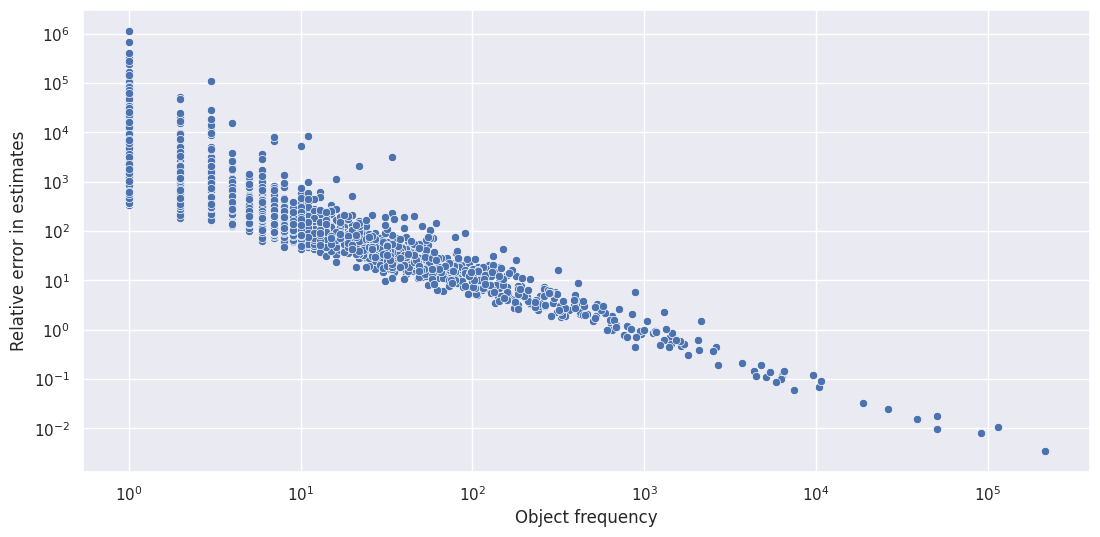

In [78]:
dataPlot = counts_real.sample(n=10_000, seed=0).select(
    pl.col("F[i]").alias("x"), (pl.col("hatF[i]") / pl.col("F[i]") - 1).alias("y")
)

# Apply the default theme
sns.set_theme()

if debugMode:
    import matplotlib.image as img

    f, (ax, ax2) = plt.subplots(1, 2, figsize=[13, 6], constrained_layout=True)
    im = img.imread(dirIn + "/loglogTiny.png")
    ax2.imshow(im, aspect="auto")
    ax2.axis("off")
else:
    f, ax = plt.subplots(1, 1, figsize=[13, 6])


sns.scatterplot(data=dataPlot, x="x", y="y", ax=ax)
ax.loglog()
# ax.set_xscale('log')
ax.set_xlabel("Object frequency")
ax.set_ylabel("Relative error in estimates")
ax.set_title("")


plt.show()

# Commento algoritmo, 5pts
>Per quali valori questo algoritmo funziona meglio?  
>In quali applicazioni potrebbe essere usato?  
---
<!-- Inizia qui la risposta -->
L'algoritmo funziona meglio quando deve stimare gli elementi molto frequenti, ovvero quando lo stream è dominato da pochi elementi molto frequenti Heavy Hitters e da una coda di elementi rari. L'errore causato dalle collisioni degli elementi rari ha un impatto trascurabile sulla stima degli elementi frequenti, garantendo un errore relativo basso per i valori più frequenti nello stream. 


Inoltre la precisione della stima è regolata dalle dimensioni della matrice dei contatori $H$:

*Aumento di $J$ (Colonne)*: Riduce l'errore sistematico $\epsilon$. Un numero alto di bucket riduce la probabilità di collisioni tra elementi diversi.

*Aumento di $K$ (Righe)*: Riduce la probabilità di fallimento $\delta$. Poiché la stima finale è il minimo tra $K$ estrazioni indipendenti, aumentare le righe rende estremamente improbabile che un elemento subisca collisioni in tutti i bucket corrispondenti.

Dato che è un algoritmo basato su contatori non decrescenti, esso non sottostima $ \hat{F}[i] \ge F[i] $. Di conseguenza, risulta pensato per applicazioni dove la sottostima è da evitare come il monitoraggio dei livelli critici o delle soglie di sicurezza.

<!-- Termina qui la risposta -->
---

# Descrizione codice (max 1 pg.), 5pts

> Descrivere i passaggi principali (coi nomi delle variabili usate) del codice visto sopra, con particolare attenzione alle fasi di streamiing e querying dell'Algoritmo 1.

---
<!-- Inizia qui la risposta -->

L'algoritmo implementato permette di stimare la frequenza degli elementi in uno stream di dati molto vasto utilizzando una struttura dati che garantisce un uso efficiente della memoria.

**Struttura dati e Parametri**
La memoria dell'algoritmo è gestita tramite una matrice di contatori H di dimensioni $K \times J$.

$K =5$: Numero di righe della matrice, corrispondenti al numero di funzioni hash indipendenti.
$J=10000$: Numero di colonne (bucket) per ciascuna riga.
hash params: Lista di coppie $(a, b)$ che definiscono le funzioni hash lineari del tipo $g_k(i) = ((a \cdot i + b) \mod 123457) \mod J$.


**Fase di Streaming (Aggiornamento)**
In questa fase, il codice elabora il file di dati fileStream a blocchi di batches per ricreare l'idea di un flow continuo. Il processo per ogni batch caricato nel DataFrame df è il seguente:
*Calcolo dell'Hash*: Per ogni riga $k$ della matrice, viene calcolato l'indice di colonna per tutti gli elementi $i$ del batch contemporaneamente. La variabile hash\_indices contiene il risultato della funzione hash applicata alla colonna degli oggetti.
*Aggregazione locale*: Utilizzando le funzioni di Polars, viene creato un DataFrame temporaneo dfH che raggruppa gli elementi per il loro valore hash group\_by("hash") e ne conta le occorrenze agg(pl.len()). Questo passaggio riduce il numero di operazioni di scrittura sulla matrice principale.
*Aggiornamento di H*: I conteggi accumulati nel batch vengono sommati alla riga $k$ della matrice H tramite l'indicizzazione avanzata di NumPy: $H[k, hash\_indices] += counts$.



**Fase di Querying (Stima)**
Una volta completato il processamento dello stream, l'algoritmo stima la frequenza per ogni oggetto $i$ presente nel DataFrame $counts\_real$.

Inizializzazione: Viene creata una colonna hatF[i] nel DataFrame dei risultati, inizializzata al valore infinito np.inf. 
*Recupero dei valori*: Per ogni funzione hash $k$, l'algoritmo calcola l'indice corrispondente per l'oggetto $i$ e legge il valore contenuto nella cella $H[k, g\_k(i)]$. Questo valore viene memorizzato temporaneamente nella variabile hash\_counter.
*Applicazione della regola del minimo*: La stima finale viene aggiornata mantenendo il valore minimo tra quelli osservati nelle varie righe: $hatF[i] = min(hatF[i], hash\_counter)$. 
L'uso della funzione $pl.min\_horizontal$ permette di confrontare efficientemente le stime fornite dalle $K$ funzioni hash, garantendo che l'errore di sovrastima dovuto alle collisioni sia ridotto secondo i limiti teorici dell'algoritmo.
<!-- Termina qui la risposta -->
---


# Modellizzazione e discussione, 10pts

> Discutere come si potrebbe costruire (e, eventualmente, stimare) un modello lineare
>$$\log\Big( \frac{\hat{F}[i]- {F}[i]}{{F}[i]} \Big)  = a \log(F[i]) + b + \varepsilon,$$
>e quali accortezze andrebbero utilizzate per la modllizzazione dell'errore $\varepsilon$. Questa domanda NON ha una risposta *esatta*, è scritta invece per riflettere su quanto assunto per i modelli lineari e alcuni dati che provengono da algoritmi.

---
<!-- Inizia qui la risposta -->
Il modello può essere stimato utilizzando i dati ottenuti dalla simulazione, dove le frequenze reali $F[i]$ sono note. 
Poichè $ P(\hat{F}[i] \leq F[i] + \epsilon t) \geq 1 - \delta $, se $\delta$ tende a zero, allora si ottiene che con probabilità quasi certa $\hat{F}[i] - F[i] \leq \epsilon t\approx \frac{et}{J}$.
Quindi si ricava che $$\log\Big(\frac{\hat{F}[i] - F[i]}{F[i]}\Big)\approx -\log(F[i])+\log\Big(\frac{et}{J}\Big)$$

Dunque $a\leq 0$ e $b=\log\Big(\frac{et}{J}\Big)$

Coefficiente $a$: Poiché l'errore assoluto del Count-Min Sketch dipende dal volume totale dello stream $t$ e dalla dimensione della memoria $J$, e non dalla singola frequenza dell'oggetto, ci si aspetta che $a$ sia negativo. All'aumentare di $F[i]$, l'impatto relativo del "rumore" dovuto alle collisioni diminuisce.


Intercetta $b$: è legata al logaritmo dell'errore di base. Questo termine è fortemente influenzato dal fatto che uno stream più denso (rapporto $t/J$ alto) traslerà verso l'alto il valore di $b$.


L'uso di una regressione lineare standard (OLS) per stimare questo modello non è teoricamente corretta, poiché diverse assunzioni statistiche vengono violate dall'algoritmo:

Asimmetria dell'errore: L'algoritmo garantisce matematicamente che $\hat{F}[i] \ge F[i]$. Pertanto, l'errore relativo non è mai negativo. Questo implica che $\varepsilon$ non può seguire una distribuzione normale centrata in zero; il modello presenta una distorsione positiva come bias.
    
Eteroschedasticità: La varianza dell'errore $\varepsilon$ non è costante. Per oggetti con bassa frequenza reale, una singola collisione con un elemento frequente causa un picco nell'errore relativo. Al contrario, per elementi frequenti, la stima è più stabile. Sarebbe dunque opportuno utilizzare i modelli pesati, come Ridge o Lasso.
    
Dipendenza Spaziale: Le osservazioni non sono indipendenti $i.i.d.$. Poiché diversi oggetti condividono fisicamente gli stessi bucket nella matrice $H$, gli errori di stima tra oggetti che collidono frequentemente risultano correlati.
<!-- Termina qui la risposta -->
---